In [7]:
#| echo: false
#imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from sklearn.datasets import load_breast_cancer
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

,Degree,Irreducible,BiasSq,Variance,Total,MSE
0,0,0.1585,2.2475,0.5068,2.9127,2.9274
1,1,0.1614,1.7996,0.2904,2.2513,2.2624
2,2,0.1580,0.0000,0.0448,0.2028,0.2029
3,3,0.1658,0.0000,0.0663,0.2321,0.2312
4,4,0.1618,0.0000,0.1860,0.3477,0.3535
5,5,0.1599,0.0006,8.0356,8.1961,8.2192
6,6,0.1629,0.0004,222.3892,222.5525,222.6619


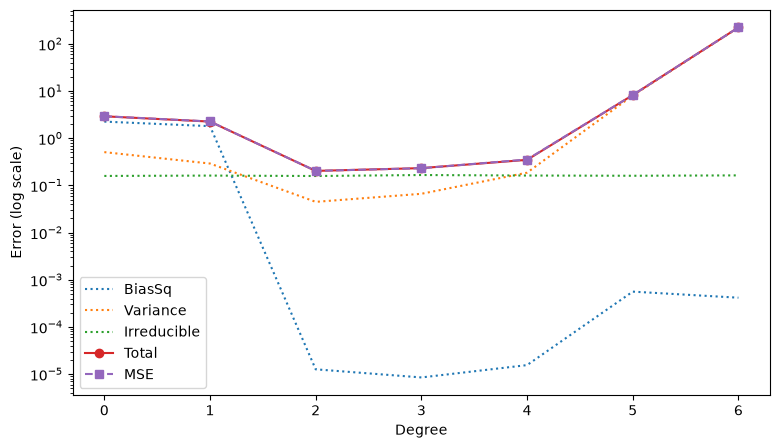

In [8]:
#| include: false
# Problem 5a
rng = np.random.default_rng(42)
f = lambda x: -2 - x + 0.5 * x**2 # the true function
n, reps, sigma = 10, 10000, 0.4 # points, training sets, noise sd
rows = []

for p in range(7): # polynomial degree
    fhat = np.empty(reps)
    for k in range(reps): # 1000 training sets of n points
        x = rng.uniform(-3, 3, n)
        y = f(x) + sigma * rng.normal(size=n)
        fhat[k] = np.polyval(np.polyfit(x, y, p), 0) # prediction at x = 0

    y0 = f(0) + sigma * rng.normal(size=reps) # test points at x = 0
    rows.append({"Degree": p, "Irreducible": np.mean((y0 - f(0))**2), "BiasSq": (fhat.mean() - f(0))**2, "Variance": fhat.var(), "MSE": np.mean((y0 - fhat)**2)})

bvd = pd.DataFrame(rows)
bvd["Total"] = bvd["Irreducible"] + bvd["BiasSq"] + bvd["Variance"]
bvd = bvd[["Degree", "Irreducible", "BiasSq", "Variance", "Total", "MSE"]]

display(bvd.round(4))
fig, ax = plt.subplots(figsize=(9, 5))

for col in ["BiasSq", "Variance", "Irreducible"]:
    ax.plot(bvd["Degree"], bvd[col], ":", label=col)

ax.plot(bvd["Degree"], bvd["Total"], "-o", label="Total")
ax.plot(bvd["Degree"], bvd["MSE"], "--s", label="MSE")

ax.set_yscale("log")
ax.set_xticks(range(7))
ax.set_xlabel("Degree")
ax.set_ylabel("Error (log scale)")
ax.legend()

plt.show()

**Problem 5a.1**

As we go from less flexible to more flexible methods:

Training error:
Gets closer to 0 as the flexibility increases because the model fits the training data better.

Test error:
First decreases as flexibility increases, but after a certain point it starts increasing again because the model overfits the training data.

Squared bias:
Squared bias starts off high but quickly drops close to 0 at degree 2, since the true function is quadratic. It stays at 0 theoretically after that.

Variance:
First decreases slightly but then increases as the model becomes more flexible, because it becomes more sensitive to the training data and noise.

Irreducible (Bayes) error:
Stays almost the same throughout, around 0.16, because it comes from random noise and does not depend on model flexibility.

**Problem 5a.2**
They are calculated in two different ways:

Total = Irreducible + BiasSq + Variance = 2.79 (Table 1)

MSE: np.mean((y0 - fhat)**2) = 2.74 (Table 1)

But both are estimated from a finite number of random simulations, so their estimates contain sampling variation.

**Problem 5a.3**

![Squared bias calculation](IMG_1984.png)

I got 2.25 and in Table 1 its 2.14 due to randomly generated training data.

**Problem 5b**

*Select splits from Table 2 that together form a valid 3-fold cross-validation, and compute the cross-validation error of each model.*

Selected split A, J and O.

For model 1: (1.2 + 2.4 + 6.0) / 3 = 3.2

For model 2: (0.3 + 0.6 + 0.6) / 3 = 0.5

For model 3: (2.1 + 2.7 + 3.0) / 3 = 2.6

*Which model do you choose, and why?*

I would choose model 2 because of the consistent low validation error.

*In general, how should you assign the data points to the folds before cross-validation, and why?*

Randomly partionionin into non-overlapping folds.

*Why is cross-validation useful when you have only a few data points?*

Because it allows the use of all data points for both training and validation across different folds. This is useful with small datasets because we don't have to permanently set aside part of the data for validation.

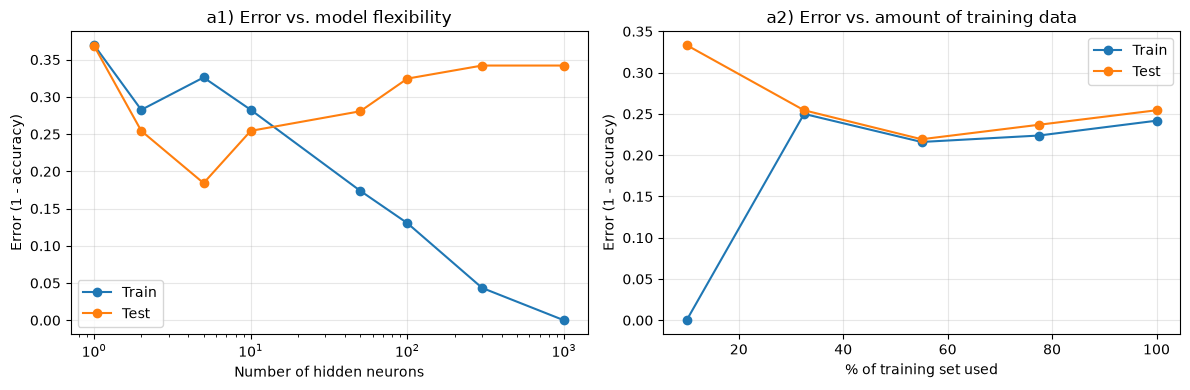

In [9]:
#| include: false
# Problem 6
warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEED = 17 # seed of every random choice
FEATURES = ["mean texture", "mean symmetry"]
data = load_breast_cancer(as_frame=True)

X = data.data[FEATURES].to_numpy()
y = data.target.to_numpy() # 0 = malignant, 1 = benign
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)

perm = np.random.default_rng(SEED).permutation(len(X_train)) # random order
idx_a = perm[:int(round(0.1 * len(X_train)))] # a1) 10%

def train_test_error(n_hidden, idx):
    """Train an MLP on the training points idx; return its training and test errors."""
    model = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(n_hidden,), max_iter=2000, alpha=0, random_state=SEED))
    model.fit(X_train[idx], y_train[idx])
    return [1 - accuracy_score(y_train[idx], model.predict(X_train[idx])), 1 - accuracy_score(y_test, model.predict(X_test))]
    
hidden = [1, 2, 5, 10, 50, 100, 300, 1000] # a1) numbers of hidden neurons
res_a1 = np.array([train_test_error(h, idx_a) for h in hidden])
fractions = np.linspace(0.1, 1.0, 5) # a2) fractions of the training set
res_a2 = np.array([train_test_error(500, perm[:int(round(f * len(X_train)))]) for f in fractions])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# a1) Error vs. model flexibility
axes[0].plot(hidden, res_a1[:, 0], "o-", label="Train")
axes[0].plot(hidden, res_a1[:, 1], "o-", label="Test")
axes[0].set_xscale("log")
axes[0].set_xlabel("Number of hidden neurons")
axes[0].set_ylabel("Error (1 - accuracy)")
axes[0].set_title("a1) Error vs. model flexibility")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# a2) Error vs. amount of training data
axes[1].plot(fractions * 100, res_a2[:, 0], "o-", label="Train")
axes[1].plot(fractions * 100, res_a2[:, 1], "o-", label="Test")
axes[1].set_xlabel("% of training set used")
axes[1].set_ylabel("Error (1 - accuracy)")
axes[1].set_title("a2) Error vs. amount of training data")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**Problem 6.a**

*Explain what you see in Figure 2: where do the networks underfit or overfit in a1, and how and why do the training and test errors change with more data in a2?*

A1 shows that the network is underfit at the start having a high train error with lower number of hidden neurons. And as the neuron amount grows it gets overfitted since training error hits 0 and test error grows.

A2 shows how the training and test errors change with more data. When 46 points are used train error hits 0 and test has the highest error yet, this is because of overfitting, when there is too little data and it knows it well. After it grows to 148 points training error increases, while test is lower. At 250 points its the highest for both. After 250 points errors get higher which tells that more training data does not guarantee a lower error.

**Problem 6.b**

*What can you say about the flexibility of each model, and how well does it generalise to the test points?*

Model 1: Not that flexible, the decision boundary is almost a straight line. It does not generalize too well either since there are many test points inside incorrect areas.

Model 2: More flexible, the decision boundary has a large U like shape curve. It generalizes well with the seperation of colored dots being in their own area but there are still test circles in the wrong area, most are but pretty close the the correct area.

Model 3: Most flexible of the three, the decision boundary shows a inregular shape in the middle of the graph. It does have training data is mostly correct but test data has many wrong, suggesting overfitting.

*How many hidden neurons do you think each model has? Compare Figure 3 with the error curves of Figure 2.*

Model flexibility: networks with 1, 2, 5, 10, 50, 100, 300 and 1000 hidden neurons, each trained on the same random 10% of the training set (46 points).

Model 1: I would say 1 or 2 hidden neurons. It does not generalize well at all. 

Model 2: Im thinking 5 or 10 hidden neurons. The generalizing works much better than the other 2 models and in figure 2 a1 the 4th point looks like this. At 5 neurons the error is the lowest so comparing the 3 models I would go with 5.

Model 3: The training error is becoming less but test has large outliers. Im guessing 300 hidden neurons since training data is mostly correct but test data has many wrong, suggesting overfitting.

**Problem 7**

*Problem 7a*

*Which link function 𝜂 is used in Poisson regression?* 

Log link function.

*Compute the expected number of bikers 𝜆(𝑋1, 𝑋2) in an hour with the temperature score 𝑋1 = 2 and a clear sky (𝑋2 = 0).*

𝛽̂0 = log 4, 𝛽̂1 = log 2 and 𝛽̂2 = log 0.25

log(lambda) = 𝛽̂0 + 𝛽̂1*X1 + 𝛽̂2*X2

log(lambda) = log 4 + 2 * log 2 + 0 = 2.77258872224

lambda = e^2.77258872224 = 16.

Expected number of bikers is 16.

*Problem 7b*

*1. Compute the expected number of bikers 𝜆(𝑋1, 𝑋2) in an hour with the temperature score 𝑋1 = 2 and a clear sky (𝑋2 = 1).*

log(lambda) = log 4 + 2 * log 2 + log 0.25 = 1.38629436112

lambda = e^1.38629436112 = 4.

Expected number of bikers is 4. Change by the factor:. 4/16 = 0.25.

*2. Show how this factor is related to the coefficient 𝛽̂^2*

When X2 changes from 0 to 1 the coefficience 𝛽̂^2 decreases to 1/4 of its original value.

*Problem 7c*

Using Poisson PMF:

P(Y=1) = (4^1*e^-4) / 1! = (4e^-4) / 1 = 0.0732625555549

Around 7.33 percent.

*Problem 7d*

In Poisson distribution: Var(Y)=lambda and we calculated number of bikers 𝜆(𝑋1, 𝑋2) in an hour with the temperature score 𝑋1 = 2 and a clear sky (𝑋2 = 1) already in 7b so  Var(𝑌 ∣ 𝑋1 = 2, 𝑋2 = 1) = 4.

With Poisson Var changes with expected count and with standard linreg Var is assumed to be constant.

**Problem 8**

*Problem 8a*

*Explain why this is one-hot encoding with one of the two levels dropped, and why you should not use both indicators of a binary feature (for example “spots” and “no spots”) together with the intercept 𝛽0.* 

Binary features need only one indicator because the other category is implied. And including both indicators and an intercept makes it so intercept is never unique.

*Suppose that wilting were instead recorded with three levels (none, mild, severe). How would you encode it?*

I would do a one-hot encoding table like:


| Wilting | Mild | Severe |
|---------|------|--------|
| None    | 0    | 0      |
| Mild    | 1    | 0      |
| Severe  | 0    | 1      |

In [10]:
#| echo: false
# Problem 8b
data = pd.read_csv("E2_tomato_train.csv")

moisture_mean = data["moisture"].mean()
moisture_std = data["moisture"].std(ddof=0)

data["moisture_std"] = (data["moisture"] - moisture_mean) / moisture_std

X = data[["moisture_std", "spots", "wilting"]]
y = data["diseased"]

#print(X.head())
#print(y.head())

lambdas = [10**6, 100, 10, 1, 0.1, 0.01, 0.001, 0]

results = []

for lam in lambdas:
    if lam == 0:
        models = {"Lambda": LogisticRegression(C=np.inf, max_iter=10000)}
    else:
        models = {
            "Ridge": LogisticRegression(C=1/lam, l1_ratio=0, max_iter=10000),
            "Lasso": LogisticRegression(C=1/lam, l1_ratio=1, solver="saga", tol=1e-8, max_iter=10**6)
        }
    for name, model in models.items():
        model.fit(X, y)

        results.append({
            "Lambda": lam,
            "Model": name,
            "Beta0": model.intercept_[0],
            "Beta1 (Moisture)": model.coef_[0, 0],
            "Beta2 (Spots)": model.coef_[0, 1],
            "Beta3 (Wilting)": model.coef_[0, 2]
        })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

     Lambda  Model     Beta0  Beta1 (Moisture)  Beta2 (Spots)  Beta3 (Wilting)
1000000.000  Ridge -0.693143          0.000003       0.000001         0.000001
1000000.000  Lasso -1.047902          0.000000       0.000000         0.000000
    100.000  Ridge -0.700973          0.033021       0.013009         0.013059
    100.000  Lasso -0.436444          0.000000       0.000000         0.000000
     10.000  Ridge -0.771866          0.258717       0.107164         0.110404
     10.000  Lasso -0.530804          0.000000       0.000000         0.000000
      1.000  Ridge -1.124158          0.886800       0.453495         0.545590
      1.000  Lasso -0.845037          1.056288       0.000000         0.000000
      0.100  Ridge -1.524627          1.275126       0.766936         1.696801
      0.100  Lasso -1.494385          1.257780       0.575972         2.459284
      0.010  Ridge -1.615331          1.295275       0.735042         3.487713
      0.010  Lasso -1.610425          1.277951      

*Problem 8b*

The table above shows the results.

For lambda = 10 and 100 Lasso reports 0 for coefficients. With lambda = 1 spots and wilting are 0.

Maximum likelihood estimate for lambda=0 does not exist because no matter how large B3 becomes it will remain zero for healthy plants so it does not matter for plants not wilting.

Software for reports a wilting coefficient of approximately 8.729 and with tolerance to tol=1e-8, the wilting coefficient increases to approximately 29.276. As you can see from below

In [11]:
model = LogisticRegression(C=np.inf, tol=1e-8, max_iter=10000)
model.fit(X, y)

print(model.intercept_)
print(model.coef_)

[-1.62389706]
[[ 1.28074482  0.69856885 29.27646861]]


## Task 8c

With very strong regularisation (λ = 10⁶), the coefficients become extremely small or exactly zero.

| Model | β₀ | β₁ (Moisture) | β₂ (Spots) | β₃ (Wilting) |
|---|---:|---:|---:|---:|
| Ridge | -0.693143 | 0.000003 | 0.000001 | 0.000001 |
| Lasso | -0.478270 | 0 | 0 | 0 |

As λ increases, the regularisation penalty becomes stronger, pushing all feature coefficients towards zero. Ridge makes the coefficients very small, while lasso can set them exactly to zero.

**Problem 9 and 10 are not done since I did not have enough time**